In [1]:
%load_ext autoreload
%autoreload 2

In [2]:
import json
from pathlib import Path
import pandas as pd

rows = [json.load(open(p)) for p in Path("models").glob("lora_*/metrics.json")]
runs = pd.DataFrame(rows).sort_values("rank")
runs[
    [
        "rank",
        "alpha",
        "trainable_params",
        "train_loss",
        "eval_loss",
        "best_step",
        "minutes",
        "peak_mem_gb",
    ]
]

,rank,alpha,trainable_params,train_loss,eval_loss,best_step,minutes,peak_mem_gb
2,4,8,2199552,1.3738,1.3303,900,18.6,11.17
1,16,32,8798208,1.3600,1.3091,900,17.9,11.25
0,64,128,35192832,1.3785,1.2978,921,18.0,11.56


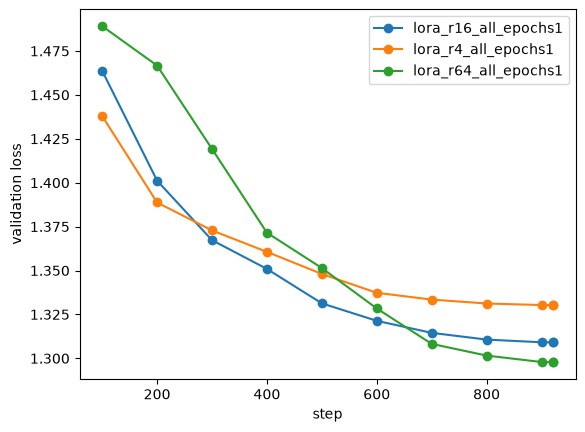

In [3]:
import matplotlib.pyplot as plt

for p in sorted(Path("models").glob("lora_*/log_history.json")):
    log = json.load(open(p))
    evals = [e for e in log if "eval_loss" in e]
    plt.plot(
        [e["step"] for e in evals],
        [e["eval_loss"] for e in evals],
        marker="o",
        label=p.parent.name,
    )
plt.xlabel("step")
plt.ylabel("validation loss")
plt.legend()
plt.show()

In [10]:
import json
from pathlib import Path
import pandas as pd


def load(pattern):
    return {p.parent.name: json.load(open(p)) for p in Path(".").glob(pattern)}


rouge = load("results/*_validation/metrics.json")
mmlu = load("results/mmlu_*/metrics.json")
train = load("models/*/metrics.json")
base_mmlu = mmlu.get("mmlu_base_1000questions", {})

rows = []
for name, m in rouge.items():
    if name.startswith(("icl_", "base_")):
        label = f"{m['shots']}-shot"
        mmlu_row = base_mmlu
        train_row = {}

    elif name.startswith("lora_"):
        run = name.split("_0shot")[0]
        r = run.split("_r")[1]
        label = f"LoRA r={r}"
        mmlu_row = mmlu.get(f"mmlu_{run}_1000questions", {})
        train_row = train.get(f"lora_r{r}_all_epochs1", {})
    elif name.startswith("full_"):
        # Full fine-tune. Its run crashed before writing metrics.json,
        # so the training numbers come from the training log instead.
        label = "Full FT"
        mmlu_row = mmlu.get("mmlu_full_1000questions", {})
        train_row = {
            "trainable_params": 494032768,  # every weight
            "minutes": 24.9,  # 24:51 min for 920/921 before ran out of memory
            "peak_mem_gb": ">14.5",
            "eval_loss": "1.312",
        }
    elif name.startswith("qlora_"):
        run = name.split("_0shot")[0] #qlora_r16
        r = run.split("_r")[1] #16
        label = f"QLoRA r={r}"
        mmlu_row = mmlu.get(f"mmlu_{run}_1000questions", {})
        train_row = train.get(f"qlora_r{r}_all_epochs1", {})
    else:
        continue
    rows.append(
        {
            "method": label,
            "rouge1": round(100 * m["rouge1"], 1),  # ×100 → the 0–100 scale papers use
            "rouge2": round(100 * m["rouge2"], 1),
            "rougeL": round(100 * m["rougeL"], 1),
            "mmlu": mmlu_row.get("accuracy"),  # already in %
            "trainable_params": train_row.get("trainable_params"),
            "train_min": train_row.get("minutes"),
            "peak_mem_gb": train_row.get("peak_mem_gb"),
            "eval_min": m["minutes"],  # time to generate + score the 818 summaries
            "eval_loss": train_row.get("eval_loss"),
        }
    )

order = [
    "0-shot",
    "1-shot",
    "3-shot",
    "5-shot",
    "LoRA r=4",
    "LoRA r=16",
    "LoRA r=64",
    "QLoRA r=16",
    "Full FT",
]
table = pd.DataFrame(rows).sort_values("method")
table = table.set_index("method").loc[order].reset_index()
table["trainable_params"] = table["trainable_params"].astype("Int64")
print(table.to_string(index=False))

    method  rouge1  rouge2  rougeL  mmlu  trainable_params  train_min peak_mem_gb  eval_min eval_loss
    0-shot    33.8    10.0    25.2  41.1              <NA>        NaN        None      18.4      None
    1-shot    35.0    11.4    27.7  41.1              <NA>        NaN        None      10.9      None
    3-shot    38.4    13.2    29.7  41.1              <NA>        NaN        None      15.9      None
    5-shot    38.9    13.8    29.8  41.1              <NA>        NaN        None      18.0      None
  LoRA r=4    47.1    20.6    37.3  40.6           2199552       18.6       11.17      20.1    1.3303
 LoRA r=16    47.2    21.3    37.6  41.8           8798208       17.9       11.25      19.9    1.3091
 LoRA r=64    47.6    21.8    38.2  35.9          35192832       18.0       11.56      21.0    1.2978
QLoRA r=16    46.5    20.0    36.7  39.4           8798208       26.4        10.9      21.2    1.3277
   Full FT    48.8    22.5    39.1  30.7         494032768       24.9       >14.5 

In [7]:
!ls results

base_0shot_validation        mmlu_full_1000questions
base_1shot_validation        mmlu_lora_r16_1000questions
base_3shot_validation        mmlu_lora_r4_1000questions
base_5shot_validation        mmlu_lora_r64_1000questions
full_0shot_validation        mmlu_qlora_r16_1000questions
lora_r16_0shot_validation    mmlu_test_200questions
lora_r4_0shot_validation     mmlu_test_20questions
lora_r64_0shot_validation    qlora_r16_0shot_validation
mmlu_base_1000questions


In [1]:
from transformers import AutoModelForCausalLM

model = AutoModelForCausalLM.from_pretrained("Qwen/Qwen2.5-0.5B-Instruct")
print(sum(p.numel() for p in model.parameters()))

/Users/fernandoquintino/Documents/CS files/DeepLearning AI courses/Small_course_projects/summ-ft/.venv/lib/python3.13/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
Loading weights: 100%|██████████| 290/290 [00:00<00:00, 5909.59it/s]


494032768


In [14]:
print(base_mmlu)
!ls results/mmlu_base_1000questions

{}
metrics.json       per_question.jsonl
